# Libraries

In [1]:
# Standard
import numpy as np
import pandas as pd

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data Science
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)
import statsmodels.api as sm
from firthmodels.adapters.statsmodels import FirthLogit
from scipy.stats import chi2
from sklearn.metrics import brier_score_loss
from sklearn.calibration import calibration_curve

# Dataset

In [2]:
df_raw = pd.read_csv("processed_data/encoded.csv")

The new variable *quit* is True when the final grade is <= 1

In [3]:
df = df_raw.copy()
df["quit"] = np.where(
    df["G3"] <= 1,
    1,
    0
)

An empirical rule of logistic regression is that one variable can describe 10 events.\
This means that not many variables can be employed to describe 16 events

# Choosing variables

In [4]:
# Initially, all variables were employed but the regression did not converge
# independent_variables = df.columns.to_list()
# independent_variables.remove("G3")
# independent_variables.remove("quit")
independent_variables = [
    "age",
    "failures",
    "studytime",
    "absences"
]
dependent_variable = ["quit"]

# Regression

The sample will be divided in train and test sub-sets

In [5]:
X = df[independent_variables]
y = df["quit"]

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [7]:
model = LogisticRegression()

model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [8]:
coefficients = pd.DataFrame({
    "Variable": X.columns,
    "Coefficient": model.coef_[0]
})

display(coefficients.sort_values(
    key=abs, 
    by="Coefficient", 
    ascending=False
    ).head(10)
)

,Variable,Coefficient
3,absences,-1.286742
2,studytime,-0.755463
0,age,0.463176
1,failures,0.437430


Interpretation:
* positive coefficients = feature increases chance of quitting
* almost null coefficients = limited contribution to quitting

In [9]:
odds_ratio = np.exp(model.coef_[0])

results = pd.DataFrame({
    "Variable": X.columns,
    "Coefficient": model.coef_[0],
    "Odds Ratio": odds_ratio
})

display(results.sort_values(
    key=abs, 
    by="Odds Ratio", 
    ascending=False
    ).head(10))

,Variable,Coefficient,Odds Ratio
0,age,0.463176,1.589113
1,failures,0.437430,1.548721
2,studytime,-0.755463,0.469793
3,absences,-1.286742,0.276169


Odds ratio is the ratio between students who quit and students who did not quit.
* Odds ratio = 1 *means no effect*
* Odds ratio > 1 *means increased chance of quitting*

In [10]:
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

print("Report:")
print(classification_report(y_test, y_pred))

y_prob = model.predict_proba(X_test)[:, 1]

print("AUC:", roc_auc_score(y_test, y_prob))

Accuracy: 0.9769230769230769
Confusion matrix:
[[127   0]
 [  3   0]]
Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       127
           1       0.00      0.00      0.00         3

    accuracy                           0.98       130
   macro avg       0.49      0.50      0.49       130
weighted avg       0.95      0.98      0.97       130

AUC: 1.0


c:\Users\Computer\miniconda3\envs\Boolean\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Computer\miniconda3\envs\Boolean\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Computer\miniconda3\envs\Boolean\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()}

Confusion matrix:
|Not quit correctly identified|Quit correctly identified|
|---|---|
|Quit not identified|False alarms|


* Accuracy = % of correct predictions
* Precision = how many students predicted to quit actually quit
* Recall = How many students who quit were actually detected
* F1-score = balance between precision and recall
* AUC = model capability to make a distinction between quitting and not quitting

In [11]:
X_stats = sm.add_constant(X)

model_significance = sm.Logit(y, X_stats)

results_significance = model_significance.fit()

print(results_significance.summary())

         Current function value: 0.070961
         Iterations: 35
                           Logit Regression Results                           
Dep. Variable:                   quit   No. Observations:                  649
Model:                          Logit   Df Residuals:                      644
Method:                           MLE   Df Model:                            4
Date:                Mon, 23 Nov 2026   Pseudo R-squ.:                  0.3863
Time:                        13:23:14   Log-Likelihood:                -46.054
converged:                      False   LL-Null:                       -75.047
Covariance Type:            nonrobust   LLR p-value:                 7.683e-12
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        -11.2149      4.104     -2.733      0.006     -19.259      -3.171
age            0.5811      0.241      2.413      0.016       0.10

c:\Users\Computer\miniconda3\envs\Boolean\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [12]:
odds_ratio = np.exp(results_significance.params)
intervals = np.exp(results_significance.conf_int())

table = pd.DataFrame({
    "Odds Ratio": odds_ratio,
    "IC 95% lower": intervals[0],
    "IC 95% upper": intervals[1],
    "P-value": results_significance.pvalues
})

display(table)

c:\Users\Computer\miniconda3\envs\Boolean\Lib\site-packages\pandas\core\internals\blocks.py:347: RuntimeWarning: overflow encountered in exp
  result = func(self.values, **kwargs)


,Odds Ratio,IC 95% lower,IC 95% upper,P-value
const,0.000013,4.325730e-09,0.041960,0.006283
age,1.787970,1.115371e+00,2.866162,0.015802
failures,2.259433,1.128571e+00,4.523451,0.021365
studytime,0.384857,1.650482e-01,0.897405,0.027066
absences,0.000013,9.608589e-320,inf,0.975687


> Results

The model is unstable:
* too few observations (quit = 1)
* the model did not converge -> p-values cannot be trusted
    * all students were classified as quit = 0
    * (huge standard error for absences)

# Firth logistical regression

More suitable for 
* few positive events
* complete separation (or quasi-separation)
* unstable coefficients in the conventional logistical regression 

In [13]:
independent_variables = [
    "age",
    "failures",
    "studytime",
    "absences",
    "G1",
    "G2"
]

dependent_variable = ["quit"]

In [14]:
X = df[independent_variables]
y = df["quit"]

In [15]:
X = sm.add_constant(X)

model = FirthLogit(y, X)
result = model.fit()

print(result.summary())

                      Firth Logistic Regression Results                       
Solver:            Newton-Raphson      No. Observations:         649
Converged:         True                No. Events:                16
No. Iterations:    21                  Df Model:                   6
Log-Likelihood:    -12.690             Df Residual:              642
                  coef   std err         z     P>|z|    [0.025    0.975]
------------------------------------------------------------------------------
       const   -2.6928    5.7780   -0.4660    0.6876  -15.9926   10.4032
         age    0.5050    0.3097    1.6308    0.1433   -0.1671    1.2635
    failures    0.2605    0.3955    0.6585    0.5610   -0.7313    1.0856
   studytime   -0.1627    0.4774   -0.3407    0.7714   -1.4823    0.8609
    absences   -1.2321    0.5076   -2.4272 4.291e-05   -3.6300   -0.3450
          G1    0.0376    0.2828    0.1330    0.9093   -0.6202    0.7173
          G2   -0.9389    0.3068   -3.0607 1.519e-05   

In [16]:
params = result.params

ci = result.conf_int()

results = pd.DataFrame({
    "Variable": X.columns,
    "Coefficient": params,
    "Odds Ratio": np.exp(params),
    "CI Lower": np.exp(ci[:, 0]),
    "CI Upper": np.exp(ci[:, 1]),
    "P-value": result.pvalues
})

print(results.round(3))

    Variable  Coefficient  Odds Ratio  CI Lower   CI Upper  P-value
0      const       -2.693       0.068     0.000  32965.193    0.688
1        age        0.505       1.657     0.846      3.538    0.143
2   failures        0.260       1.298     0.481      2.961    0.561
3  studytime       -0.163       0.850     0.227      2.365    0.771
4   absences       -1.232       0.292     0.027      0.708    0.000
5         G1        0.038       1.038     0.538      2.049    0.909
6         G2       -0.939       0.391     0.167      0.713    0.000


## Evaluating the model

Since there are only 16 events, sub-sets of test-train would only include 3 events on average, being quite unstable.\
Plus, the main goal is to identify variables with highest influence on the outcome, not predicting

### Significativity of the model

Comparing:
* null model = only intercept
* full model

Global Wald test, instead of comparing individual p-values of coefficients.

In [17]:
beta = np.asarray(result.params)[1:]

cov = np.asarray(result.cov_params())[1:, 1:]

W = beta.T @ np.linalg.inv(cov) @ beta

df_test = len(beta)

p_value = chi2.sf(W, df_test)

print("Global Wald test")
print("Chi-square:", W)
print("Degrees of freedom:", df_test)
print("P-value:", p_value)

Global Wald test
Chi-square: 25.097461923855484
Degrees of freedom: 6
P-value: 0.0003275533604265059


### Odds Ratio confidence intervals

* OR = 1 -> no association
* OR > 1 -> positive association
* OR < 1 -> negative association
* OR contains 1 -> association not statistically significant

### Goodness of fit and calibration

Brier score. When close to 1, the accuracy of predictions is low. When close to 0, the accuracy is high

In [18]:
y_pred_prob = result.predict(X)

brier = brier_score_loss(y, y_pred_prob)

print("Brier Score:", brier)

Brier Score: 0.008269552262601882


Calibration plot:
* diagonal = perfect calibration
* curve above diagonal = model underestimates the probability of events

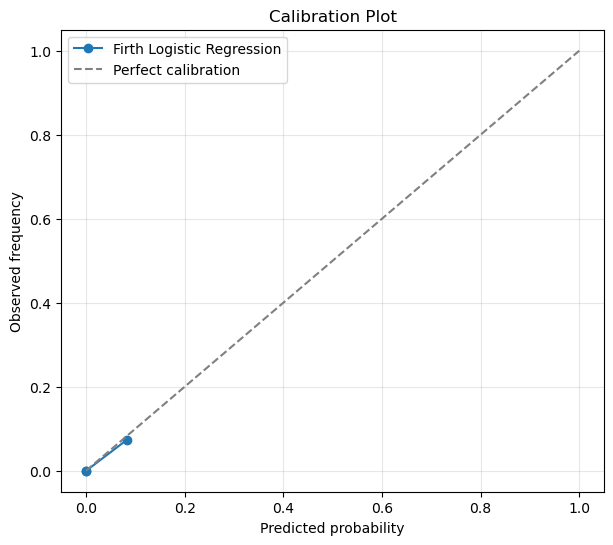

In [19]:
fraction_positive, mean_predicted = calibration_curve(
    y,
    y_pred_prob,
    n_bins=3,
    strategy="quantile"
)

plt.figure(figsize=(7, 6))

plt.plot(
    mean_predicted,
    fraction_positive,
    marker="o",
    label="Firth Logistic Regression"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Perfect calibration"
)

plt.xlabel("Predicted probability")
plt.ylabel("Observed frequency")
plt.title("Calibration Plot")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Conclusions

> Issue with number of events

The fraction of positive events (quit = 1) `is too little to have a stable model`.